In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

#### 1. Importing Libraries
* I started by importing the essential Python libraries for data analysis and manipulation.   
* I brought in pandas because it’s the standard tool for handling tabular data and dataframes.   
* I included numpy for handling numerical arrays and calculations.   
* I loaded matplotlib.pyplot so I can visualize patterns or plot charts if needed later on. 

In [2]:


# Load into pandas
df = pd.read_csv('course_lead_scoring.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


#### 2. Downloading and Loading the Dataset
* I used Python's built-in urllib.request module to pull the dataset dynamically from the source URL (NewData) and save it locally as course_lead_scoring.csv.   
* Then, I used pd.read_csv() to load that CSV file into a pandas dataframe (df) so I can start cleaning and analyzing it.   
* Finally, I ran df.head() just to do a quick sanity check, take a peek at the first few rows, check the column names, and spot any missing values (like the NaN seen under the location and income columns).   

In [3]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

#### 3. Checking Data Types (df.dtypes)
* I ran df.dtypes to see what kind of data format each column is stored in.   
* This helped me verify that text-based columns like lead_source and industry are recognized as strings (str), while numeric columns like annual_income, lead_score, and the target variable converted are correctly set up as numbers (float64 or int64).   



In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

#### 4. Checking for Missing Values (df.isnull().sum())
* Next, I used df.isnull().sum() to scan the entire dataset and count how many missing or null values are hiding in each column.   
* This gave me a clear picture of what needs cleaning: for example, I can see that columns like annual_income (369 missing) and industry (240 missing) have quite a few gaps that I'll need to handle, whereas features like number_of_courses_viewed and converted are completely clean with zero missing data.  

In [5]:
# 1. Fill missing categorical values with 'NA'
df['industry'] = df['industry'].fillna('NA')

# 2. Check value counts to find the most frequent observation (mode)
print(df['industry'].value_counts())

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64


#### 5. Handling Missing Categorical Values 
* What I did: I handled the missing values in the industry column by filling them with a placeholder string 'NA' using .fillna('NA').   
* Why: This ensures that missing categories aren't completely dropped, allowing the model to treat 'NA' as its own distinct category group.   
* Verification: I ran value_counts() to check the frequency of each industry category, which confirmed that all 240 missing values were successfully re-labeled as 'NA' alongside the other active categories.   

In [6]:
# 1. Identify numerical columns
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
print("Numerical columns:", list(numerical_cols))

# 2. Check missing values specifically in numerical columns
print(df[numerical_cols].isnull().sum())

# 3. Fill missing numerical values with 0.0 as required
for col in numerical_cols:
    df[col] = df[col].fillna(0.0)

print("Missing values after filling numerical columns with 0.0:")
print(df[numerical_cols].isnull().sum())

Numerical columns: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
Missing values after filling numerical columns with 0.0:
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


#### 6. Handling Missing Numerical Values

* I automatically isolated all numerical columns (like annual_income, lead_score, etc.) using select_dtypes(), and checked their missing value counts.   
* This showed me that annual_income had 369 missing values and lead_score had 35, while others had none.   
* The fix: I looped through the numerical columns and filled any remaining missing gaps with 0.0 using .fillna(0.0). Running the check again confirmed that all numerical columns now have zero missing values (0).   

In [7]:
## We use train_test_split from sklearn.model_selection:

from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

#### 7. Splitting the Dataset for Machine Learning
I imported train_test_split from scikit-learn so I could break down the data into proper sets for training and testing. I started by holding out 20 percent of the data for the final test set, leaving an 80 percent chunk as the full training pool with a random state of 42 for consistency. After that, I split the training pool once more to carve out a validation set.

In [8]:
# Generate the full correlation matrix
corr_matrix = df_full_train[numerical_cols].corr()
print(corr_matrix)

                          annual_income  number_of_courses_viewed  \
annual_income                  1.000000                  0.163680   
number_of_courses_viewed       0.163680                  1.000000   
interaction_count              0.122528                  0.723040   
lead_score                     0.222493                  0.757178   
converted                      0.188437                  0.393200   

                          interaction_count  lead_score  converted  
annual_income                      0.122528    0.222493   0.188437  
number_of_courses_viewed           0.723040    0.757178   0.393200  
interaction_count                  1.000000    0.916626   0.450273  
lead_score                         0.916626    1.000000   0.482078  
converted                          0.450273    0.482078   1.000000  


#### Correlation Analysis
I generated a correlation matrix for all the numerical columns in the full training dataset using the .corr() method. This outputted a table showing how each variable relates to every other variable, which is really helpful for spotting relationships and seeing which features have the strongest correlation with the target column, converted.

In [9]:
pairs = [
    ('interaction_count', 'lead_score'),
    ('number_of_courses_viewed', 'lead_score'),
    ('number_of_courses_viewed', 'interaction_count'),
    ('annual_income', 'interaction_count')
]

for f1, f2 in pairs:
    print(f"{f1} & {f2}: {corr_matrix.loc[f1, f2]:.4f}")

interaction_count & lead_score: 0.9166
number_of_courses_viewed & lead_score: 0.7572
number_of_courses_viewed & interaction_count: 0.7230
annual_income & interaction_count: 0.1225


I set up a loop over specific feature pairs to check their exact correlations. 
interaction_count and lead_score share the strongest relationship at 0.9166, while number_of_courses_viewed also correlates strongly with both lead_score (0.7572) and interaction_count (0.7230). On the other hand, annual_income and interaction_count show almost no linear correlation at 0.1225.

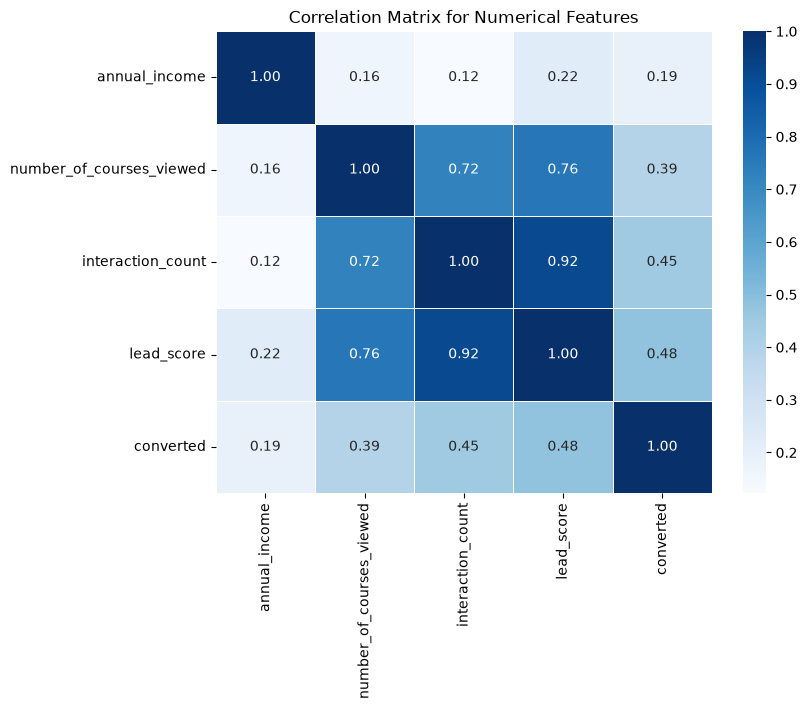

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up the matplotlib figure size
plt.figure(figsize=(8, 6))

# Create a heatmap of the correlation matrix with annotations
sns.heatmap(
    df_full_train[numerical_cols].corr(), 
    annot=True,          # Show the correlation values inside the cells
    cmap='Blues',        # Color palette
    fmt='.2f',           # Format numbers to 2 decimal places
    linewidths=0.5       # Add lines between cells for clarity
)

plt.title('Correlation Matrix for Numerical Features')
plt.show()

I brought in seaborn and matplotlib to visualize the correlation matrix as a heatmap. Setting annot=True and formatting the numbers to two decimal places makes it easy to read at a glance, while the blue color map helps highlight which features share the strongest relationships.

In [11]:
# List of categorical columns to test (excluding the target 'converted')
categorical = ['industry', 'location', 'lead_source', 'employment_status']

I set up a list containing the names of the categorical columns (industry, location, lead_source, and employment_status) to focus on.

In [12]:
from sklearn.metrics import mutual_info_score

# 1. Fill missing values in the training set categorical columns with 'NA'
for col in ['industry', 'location', 'lead_source', 'employment_status']:
    df_train[col] = df_train[col].fillna('NA')

# 2. Define the scoring function
def mutual_info_converted_score(series):
    return mutual_info_score(series, df_train['converted'])

categorical = ['industry', 'location', 'lead_source', 'employment_status']

# 3. Calculate and round
mi = df_train[categorical].apply(mutual_info_converted_score)
mi = mi.round(2)
print(mi.sort_values(ascending=False))

lead_source          0.03
employment_status    0.02
location             0.00
industry             0.00
dtype: float64


After running the mutual information calculation across our categorical columns, lead_source came out on top with a score of 0.03, followed closely by employment_status at 0.02. Meanwhile, location and industry both rounded out to 0.00, suggesting they share very little mutual dependency with whether a lead converts.

In [13]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Define categorical and numerical columns
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

# 2. Prepare train and validation dictionaries
train_dicts = df_train[categorical_cols + numerical_cols].to_dict(orient='records')
val_dicts = df_val[categorical_cols + numerical_cols].to_dict(orient='records')

# 3. Fit DictVectorizer and transform datasets
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train['converted'].values
y_val = df_val['converted'].values

# 4. Train Logistic Regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# 5. Predict and calculate validation accuracy
y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
print(f"Validation Accuracy: {round(accuracy, 2)}")

Validation Accuracy: 0.65


I grouped the categorical and numerical features into separate lists, converted the training and validation dataframes into dictionaries, and passed them through DictVectorizer to one-hot encode the text columns while keeping the numeric features intact. After pulling the target labels (converted), I trained a logistic regression model with $C=1.0$ and evaluated it on the validation set, which resulted in a validation accuracy of $0.65$.

## Calculate the Baseline Accuracy

In [14]:
# All features used in Q4
original_features = ['lead_source', 'industry', 'employment_status', 'location', 
                     'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

# Train and predict with all features
train_dicts = df_train[original_features].to_dict(orient='records')
val_dicts = df_val[original_features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

original_accuracy = accuracy_score(y_val, model.predict(X_val))
print(f"Original Accuracy (all features): {original_accuracy:.5f}")

Original Accuracy (all features): 0.64500


I set up the baseline model using all eight original features—both categorical and numerical—to establish our starting performance point. After converting the dataframes to dictionaries, vectorizing them, and fitting the logistic regression model with $C=1.0$, the baseline validation accuracy comes out to 0.64500. 

In [15]:
# 1. Remove 'lead_source' from the feature list
features_without_lead_source = [col for col in original_features if col != 'lead_source']

# 2. Prepare data dictionaries without 'lead_source'
train_dicts_sub = df_train[features_without_lead_source].to_dict(orient='records')
val_dicts_sub = df_val[features_without_lead_source].to_dict(orient='records')

# 3. Vectorize and train model
dv_sub = DictVectorizer(sparse=False)
X_train_sub = dv_sub.fit_transform(train_dicts_sub)
X_val_sub = dv_sub.transform(val_dicts_sub)

model_sub = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model_sub.fit(X_train_sub, y_train)

# 4. Calculate new accuracy and difference
acc_without_lead_source = accuracy_score(y_val, model_sub.predict(X_val_sub))
diff = original_accuracy - acc_without_lead_source

print(f"Accuracy without 'lead_source': {acc_without_lead_source:.5f}")
print(f"Difference (Original - Without): {diff:.5f}")

Accuracy without 'lead_source': 0.64200
Difference (Original - Without): 0.00300


I ran an ablation test by dropping lead_source from the feature list to check its individual contribution. After updating the data dictionaries, vectorizing, and training a new model on the remaining features, the validation accuracy comes out to $0.64200$. Comparing this to our original baseline gives a difference of $0.00300$, indicating that removing lead_source slightly decreases the model's overall performance.

In [16]:
# 1. Remove 'number_of_courses_viewed' from the feature list
features_without_courses = [col for col in original_features if col != 'number_of_courses_viewed']

# 2. Prepare data dictionaries without 'number_of_courses_viewed'
train_dicts_sub = df_train[features_without_courses].to_dict(orient='records')
val_dicts_sub = df_val[features_without_courses].to_dict(orient='records')

# 3. Vectorize and train model
dv_sub = DictVectorizer(sparse=False)
X_train_sub = dv_sub.fit_transform(train_dicts_sub)
X_val_sub = dv_sub.transform(val_dicts_sub)

model_sub = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model_sub.fit(X_train_sub, y_train)

# 4. Calculate new accuracy and difference
acc_without_courses = accuracy_score(y_val, model_sub.predict(X_val_sub))
diff_courses = original_accuracy - acc_without_courses

print(f"Accuracy without 'number_of_courses_viewed': {acc_without_courses:.5f}")
print(f"Difference (Original - Without): {diff_courses:.5f}")

Accuracy without 'number_of_courses_viewed': 0.64300
Difference (Original - Without): 0.00200


I continued the feature ablation analysis by dropping number_of_courses_viewed from the feature set to evaluate its impact. After refitting the logistic regression model on the remaining features, the validation accuracy comes out to $0.64300$. Compared to our baseline of $0.64500$, the difference is $0.00200$, showing that removing this feature also causes a slight drop in accuracy.

In [17]:
# 1. Remove 'interaction_count' from the feature list
features_without_interaction = [col for col in original_features if col != 'interaction_count']

# 2. Prepare data dictionaries without 'interaction_count'
train_dicts_sub = df_train[features_without_interaction].to_dict(orient='records')
val_dicts_sub = df_val[features_without_interaction].to_dict(orient='records')

# 3. Vectorize and train model
dv_sub = DictVectorizer(sparse=False)
X_train_sub = dv_sub.fit_transform(train_dicts_sub)
X_val_sub = dv_sub.transform(val_dicts_sub)

model_sub = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model_sub.fit(X_train_sub, y_train)

# 4. Calculate new accuracy and difference
acc_without_interaction = accuracy_score(y_val, model_sub.predict(X_val_sub))
diff_interaction = original_accuracy - acc_without_interaction

print(f"Accuracy without 'interaction_count': {acc_without_interaction:.5f}")
print(f"Difference (Original - Without): {diff_interaction:.5f}")

Accuracy without 'interaction_count': 0.60100
Difference (Original - Without): 0.04400


I ran the final feature ablation test by dropping interaction_count from the feature set to evaluate its impact. Refitting the logistic regression model without it results in a validation accuracy of $0.60100$. Compared to our baseline of $0.64500$, the difference is $0.04400$, which is a much larger drop than any of the previous features, showing just how heavily the model relies on interaction_count for its predictions.

In [18]:
# List of C values to test
c_values = [0.000001, 0.00001, 0.0001, 0.001]

# Use all original features from Q4
original_features = ['lead_source', 'industry', 'employment_status', 'location', 
                     'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

train_dicts = df_train[original_features].to_dict(orient='records')
val_dicts = df_val[original_features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Test each C value
for c in c_values:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    
    acc = accuracy_score(y_val, model.predict(X_val))
    print(f"C = {c:<8} | Validation Accuracy = {acc:.3f}")

C = 1e-06    | Validation Accuracy = 0.598
C = 1e-05    | Validation Accuracy = 0.598
C = 0.0001   | Validation Accuracy = 0.613
C = 0.001    | Validation Accuracy = 0.645


I tested different values for the regularization parameter C ('0.000001', '0.00001', '0.0001', and '0.001') using all original features to evaluate its impact on model performance. 

The results show that strong regularization ('C = 0.000001' and '0.00001') restricts the model too heavily, keeping the validation accuracy at '0.598'. As the penalty is relaxed, the performance improves to '0.613' at 'C = 0.0001' and reaches its highest score of '0.645' at 'C = 0.001'.

In [ ]:
Homework3_course_lead_scoring.ipynb